# Final Project: Predicting Large Company Layoffs (2019–2026)

**Name:** Umang Patel  
**Course:** AIT 620: Methods of Artificial Intelligence and Machine Learning  
**Professor:** Dr. Fuat Akal  
**Date:** October 25, 2026

## Dataset

The data comes from **Kaggle** (Layoffs 2019–2026 dataset). I use the sample file with **5,000 layoff events**. Each row is one layoff that was reported in the news.

Main columns:

| Column | Meaning |
|---|---|
| date, year, month | When the layoff was reported |
| company_name | Name of the company |
| country, company_country, company_state, company_city | Where it happened / where the company is based |
| sector | Industry of the company |
| headcount_cut | Number of people laid off (only when verified) |
| headcount_status | verified, not_disclosed, or failed_check |
| pct_workforce | Percent of the workforce cut |
| is_furlough | True if it was a temporary furlough |
| news_mentions | How many news articles mentioned the layoff |
| news_source, news_url, news_excerpt | The news article it came from |

The CSV file (`layoffs_2019_2026_sample.csv`) is saved in the same folder as this notebook, so the notebook runs on its own.

In [1]:
# ---- Import libraries ----
# libraries used in this project
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# chart style and table display settings
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 6)
pd.set_option("display.max_colwidth", 15)

In [2]:
# ---- Load the data ----
# load the dataset
df = pd.read_csv("layoffs_2019_2026_sample.csv")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (5000, 20)


,layoff_id,date,year,...,news_url,news_excerpt,fliar_profile_url
0,3eabf5c11805,2019-01-04,2019,...,NaN,Popular's i...,NaN
1,964aaab244e9,2019-01-04,2019,...,https://www...,Selecta Bio...,https://fli...
2,b8fd1f9ace14,2019-01-05,2019,...,https://www...,"Avianca, an...",https://fli...
3,584e07d6a013,2019-01-07,2019,...,https://www...,According t...,https://fli...
4,958daea74c55,2019-01-07,2019,...,https://tim...,"Last year, ...",https://fli...


In [3]:
# ---- Exploratory data analysis ----
# data type and number of missing values for each column
info_table = pd.DataFrame(
    {
        "data_type": df.dtypes.astype(str),
        "missing": df.isnull().sum(),
        "missing_%": (df.isnull().mean() * 100).round(1),
        "unique_values": df.nunique(),
    }
)
info_table

,data_type,missing,missing_%,unique_values
layoff_id,str,0,0.0,5000
date,str,0,0.0,1867
year,int64,0,0.0,8
month,str,0,0.0,90
company_name,str,0,0.0,3497
company_domain,str,1265,25.3,2374
country,str,470,9.4,112
company_country,str,1645,32.9,83
company_state,str,2933,58.7,57
company_city,str,1560,31.2,917


In [4]:
# how many layoffs have a verified headcount
df["headcount_status"].value_counts().to_frame("count")

,count
headcount_status,
verified,2489
failed_check,1314
not_disclosed,1197


In [5]:
# summary of the number columns
df[
    ["year", "headcount_cut", "pct_workforce", "news_mentions"]
].describe().round(1)

,year,headcount_cut,pct_workforce,news_mentions
count,5000.0,2489.0,1121.0,5000.0
mean,2022.5,1120.5,22.1,5.7
std,2.2,3392.3,20.0,32.4
min,2019.0,1.0,0.1,1.0
25%,2020.0,76.0,9.0,1.0
50%,2023.0,200.0,15.0,1.0
75%,2024.0,650.0,30.0,3.0
max,2026.0,80000.0,95.0,1530.0


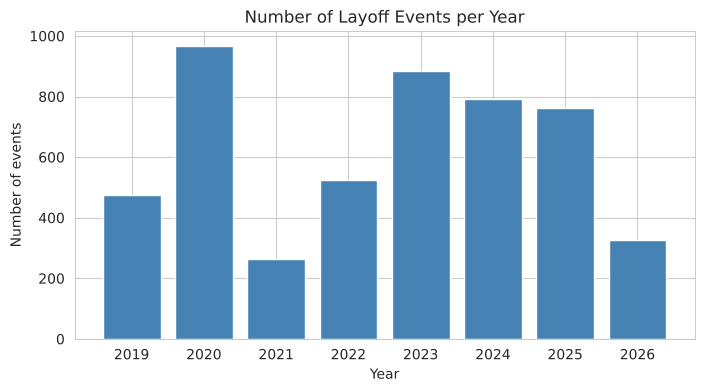

,events
year,
2019,476
2020,968
2021,265
2022,525
2023,885
2024,791
2025,762
2026,328


In [6]:
# count of layoff events in each year
events_per_year = df["year"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
plt.bar(
    events_per_year.index, events_per_year.values, color="steelblue"
)
plt.title("Number of Layoff Events per Year")
plt.xlabel("Year")
plt.ylabel("Number of events")
plt.show()

events_per_year.to_frame("events")

In [7]:
# the 5 busiest months
df["month"].value_counts().head(5).to_frame("events")

,events
month,
2020-04,165
2020-03,136
2023-01,120
2020-07,99
2020-05,98


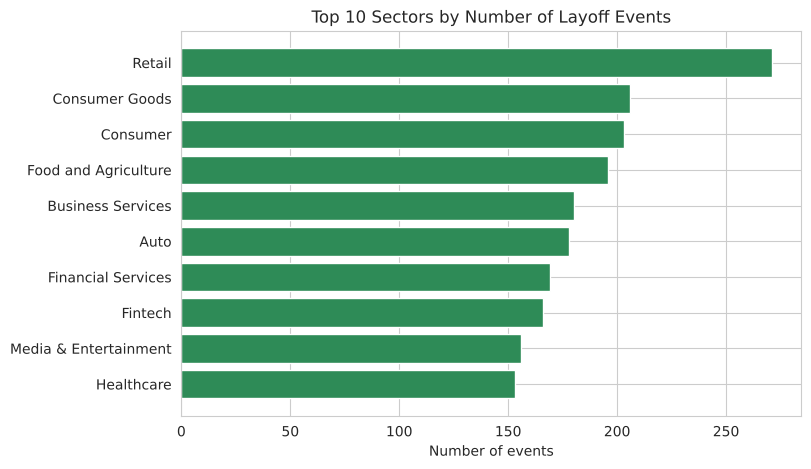

In [8]:
# 10 sectors with the most layoff events
top_sectors = df["sector"].value_counts().head(10)

plt.figure(figsize=(8, 5))
plt.barh(
    top_sectors.index[::-1], top_sectors.values[::-1], color="seagreen"
)
plt.title("Top 10 Sectors by Number of Layoff Events")
plt.xlabel("Number of events")
plt.show()

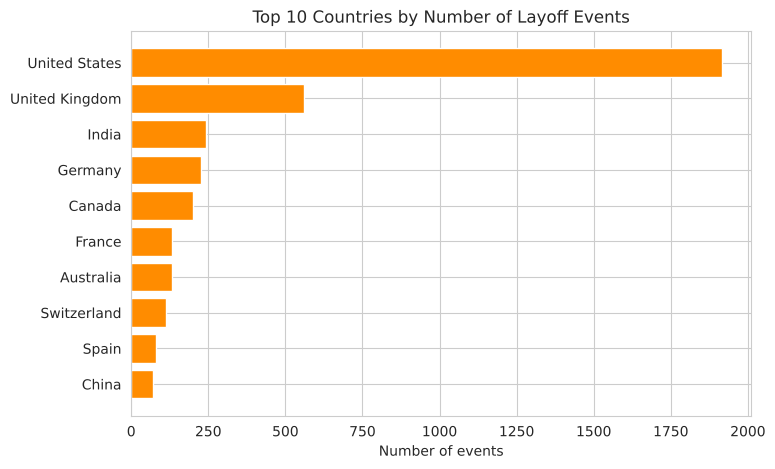

In [9]:
# 10 countries with the most layoff events
top_countries = df["country"].value_counts().head(10)

plt.figure(figsize=(8, 5))
plt.barh(
    top_countries.index[::-1],
    top_countries.values[::-1],
    color="darkorange",
)
plt.title("Top 10 Countries by Number of Layoff Events")
plt.xlabel("Number of events")
plt.show()

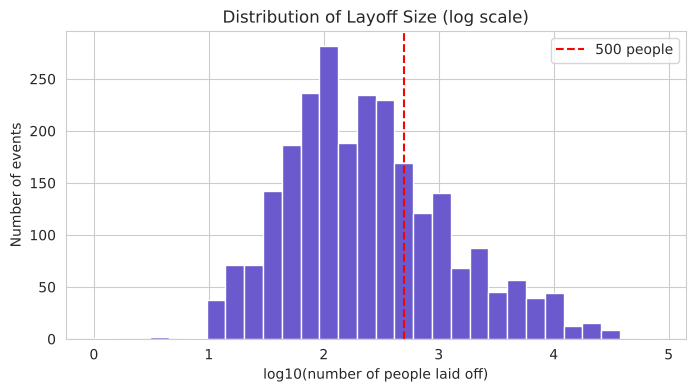

In [10]:
# only rows where the headcount is known
known = df[df["headcount_cut"].notna()]

plt.figure(figsize=(8, 4))
plt.hist(
    np.log10(known["headcount_cut"]),
    bins=30,
    color="slateblue",
    edgecolor="white",
)
plt.axvline(
    np.log10(500), color="red", linestyle="--", label="500 people"
)
plt.title("Distribution of Layoff Size (log scale)")
plt.xlabel("log10(number of people laid off)")
plt.ylabel("Number of events")
plt.legend()
plt.show()

In [11]:
# median layoff size in each year
known.groupby("year")["headcount_cut"].median().to_frame(
    "median_headcount_cut"
)

,median_headcount_cut
year,
2019,200.0
2020,300.0
2021,210.0
2022,142.0
2023,169.0
2024,175.0
2025,200.0
2026,153.0


In [12]:
# relationship between news coverage and layoff size (log values)
print(
    "Correlation:",
    round(
        np.corrcoef(
            np.log1p(known["news_mentions"]),
            np.log1p(known["headcount_cut"]),
        )[0, 1],
        3,
    ),
)

Correlation: 0.285


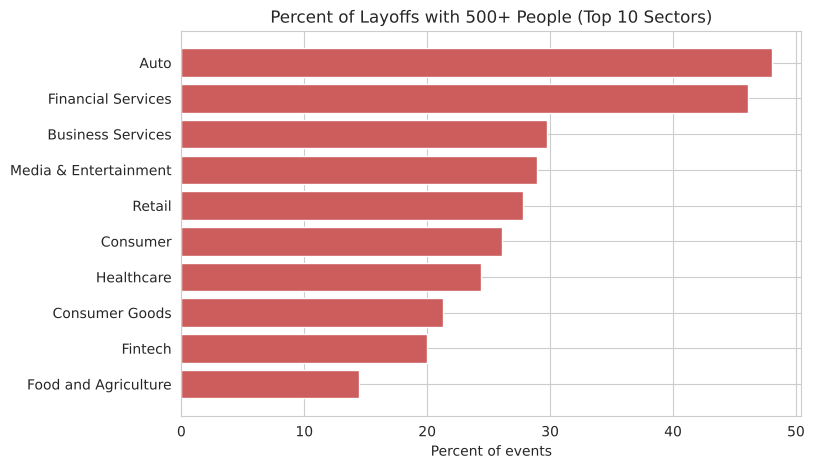

In [13]:
# percent of large layoffs (500+) in the 10 biggest sectors
known_sector = known[known["sector"].isin(top_sectors.index)]
large_rate = (known_sector["headcount_cut"] >= 500).groupby(
    known_sector["sector"]
).mean().sort_values() * 100

plt.figure(figsize=(8, 5))
plt.barh(large_rate.index, large_rate.values, color="indianred")
plt.title("Percent of Layoffs with 500+ People (Top 10 Sectors)")
plt.xlabel("Percent of events")
plt.show()

In [14]:
# ---- Data preparation ----
# number of layoff events per company (counted on the full dataset)
df["company_events"] = df.groupby("company_name")[
    "layoff_id"
].transform("count")

# keep only rows with a verified headcount
data = df[df["headcount_cut"].notna()].copy()

# target: 1 = large layoff (500 or more people)
data["large_layoff"] = (data["headcount_cut"] >= 500).astype(int)

# new features
data["month_num"] = pd.to_datetime(data["date"]).dt.month
data["log_news"] = np.log1p(data["news_mentions"])
data["has_domain"] = data["company_domain"].notna().astype(int)
data["is_furlough"] = data["is_furlough"].astype(int)

# fill missing categories
data["sector"] = data["sector"].fillna("Unknown")
data["country"] = data["country"].fillna("Unknown")

print("Rows used for modeling:", len(data))
data["large_layoff"].value_counts().to_frame("count")

Rows used for modeling: 2489


,count
large_layoff,
0,1732
1,757


In [15]:
# features and target
numeric_features = [
    "year",
    "month_num",
    "log_news",
    "company_events",
    "has_domain",
    "is_furlough",
]
categorical_features = ["sector", "country"]

X = data[numeric_features + categorical_features]
y = data["large_layoff"]

# 80% training data, 20% test data
# (keep the same share of large layoffs in both)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 1991
Test rows: 498


In [16]:
# scale the number columns and one-hot encode the categories
# rare sectors/countries (fewer than 20 rows) are grouped together
preprocess = ColumnTransformer(
    [
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", min_frequency=20),
            categorical_features,
        ),
    ]
)

In [17]:
# ---- Model building and cross-validation ----
# the models to compare
models = {
    "Dummy (baseline)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

# 5-fold cross-validation on the training data
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []

for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    auc = cross_val_score(
        pipe, X_train, y_train, cv=cv, scoring="roc_auc"
    )
    f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    acc = cross_val_score(
        pipe, X_train, y_train, cv=cv, scoring="accuracy"
    )
    cv_results.append(
        {
            "model": name,
            "cv_accuracy": acc.mean(),
            "cv_f1": f1.mean(),
            "cv_roc_auc": auc.mean(),
            "roc_auc_std": auc.std(),
        }
    )

cv_table = pd.DataFrame(cv_results).set_index("model").round(3)
cv_table

,cv_accuracy,cv_f1,cv_roc_auc,roc_auc_std
model,,,,
Dummy (baseline),0.696,0.000,0.500,0.000
Logistic Regression,0.643,0.505,0.702,0.024
Decision Tree,0.664,0.513,0.683,0.031
Random Forest,0.679,0.533,0.725,0.029
Gradient Boosting,0.733,0.379,0.717,0.025


In [18]:
# ---- Evaluation on the test set ----
# train each model and score it on the test set
test_results = []
fitted = {}

for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    test_results.append(
        {
            "model": name,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred),
            "roc_auc": roc_auc_score(y_test, prob),
        }
    )

test_table = pd.DataFrame(test_results).set_index("model").round(3)
test_table

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Dummy (baseline),0.697,0.000,0.000,0.000,0.500
Logistic Regression,0.657,0.448,0.576,0.504,0.699
Decision Tree,0.693,0.493,0.464,0.478,0.671
Random Forest,0.691,0.492,0.609,0.544,0.724
Gradient Boosting,0.737,0.647,0.291,0.402,0.732


In [19]:
# pick the model with the highest cross-validation ROC AUC
# (chosen from the training data, so the test set
# stays a fair final check)
best_name = cv_table["cv_roc_auc"].idxmax()
best_model = fitted[best_name]
print("Best model:", best_name)

best_pred = best_model.predict(X_test)
print(
    classification_report(
        y_test, best_pred, target_names=["Small (<500)", "Large (500+)"]
    )
)

Best model: Random Forest
              precision    recall  f1-score   support

Small (<500)       0.81      0.73      0.77       347
Large (500+)       0.49      0.61      0.54       151

    accuracy                           0.69       498
   macro avg       0.65      0.67      0.66       498
weighted avg       0.71      0.69      0.70       498



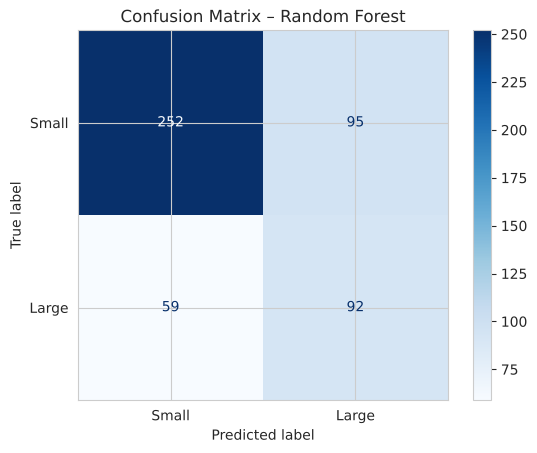

In [20]:
# confusion matrix of the best model
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, display_labels=["Small", "Large"], cmap="Blues"
)
plt.title("Confusion Matrix – " + best_name)
plt.show()

In [21]:
# ---- Feature importance ----
# feature importance from the random forest (top 12)
rf = fitted["Random Forest"]
feature_names = rf.named_steps["prep"].get_feature_names_out()
importances = pd.Series(
    rf.named_steps["model"].feature_importances_, index=feature_names
)
importances.sort_values(ascending=False).head(12).round(3).to_frame(
    "importance"
)

,importance
num__log_news,0.238
num__company_events,0.156
num__year,0.091
num__month_num,0.091
cat__country_United States,0.063
cat__sector_Food and Agriculture,0.024
cat__country_infrequent_sklearn,0.021
num__is_furlough,0.019
"cat__sector_Aerospace, Maritime and Defense",0.017
num__has_domain,0.016
